In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
from collections import Counter
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, label_binarize, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve, auc, roc_auc_score
from sklearn.multiclass import OneVsRestClassifier
# Prepare data
import warnings
warnings.filterwarnings("ignore")
print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Load the dataset
file_path = r"C:\Users\Dell\OneDrive\Desktop\internship\Medicine_Details.csv"
df = pd.read_csv(file_path)

In [3]:
print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset loaded successfully!
Rows: 11825
Columns: 9


In [4]:
display(df.head())

,Medicine Name,Composition,Uses,Side_effects,Image URL,Manufacturer,Excellent Review %,Average Review %,Poor Review %
0,Avastin 400mg Injection,Bevacizumab (400mg),Cancer of colon and rectum Non-small cell lun...,Rectal bleeding Taste change Headache Noseblee...,"https://onemg.gumlet.io/l_watermark_346,w_480,...",Roche Products India Pvt Ltd,22,56,22
1,Augmentin 625 Duo Tablet,Amoxycillin (500mg) + Clavulanic Acid (125mg),Treatment of Bacterial infections,Vomiting Nausea Diarrhea Mucocutaneous candidi...,"https://onemg.gumlet.io/l_watermark_346,w_480,...",Glaxo SmithKline Pharmaceuticals Ltd,47,35,18
2,Azithral 500 Tablet,Azithromycin (500mg),Treatment of Bacterial infections,Nausea Abdominal pain Diarrhea,"https://onemg.gumlet.io/l_watermark_346,w_480,...",Alembic Pharmaceuticals Ltd,39,40,21
3,Ascoril LS Syrup,Ambroxol (30mg/5ml) + Levosalbutamol (1mg/5ml)...,Treatment of Cough with mucus,Nausea Vomiting Diarrhea Upset stomach Stomach...,"https://onemg.gumlet.io/l_watermark_346,w_480,...",Glenmark Pharmaceuticals Ltd,24,41,35
4,Aciloc 150 Tablet,Ranitidine (150mg),Treatment of Gastroesophageal reflux disease (...,Headache Diarrhea Gastrointestinal disturbance,"https://onemg.gumlet.io/l_watermark_346,w_480,...",Cadila Pharmaceuticals Ltd,34,37,29


In [5]:
df.tail()

,Medicine Name,Composition,Uses,Side_effects,Image URL,Manufacturer,Excellent Review %,Average Review %,Poor Review %
11820,Zilarta-CT 40/6.25 Tablet,Azilsartan medoxomil (40mg) + Chlorthalidone (...,Hypertension (high blood pressure),Dizziness Tiredness Decreased potassium level ...,"https://onemg.gumlet.io/l_watermark_346,w_480,...",Micro Labs Ltd,67,33,0
11821,Zipcoz Tablet,Chromium Picolinate (100mcg) + D-Chiro Inosito...,Polycystic ovarian syndrome (PCOS),Rash Nausea Paresthesia tingling or pricking s...,"https://onemg.gumlet.io/l_watermark_346,w_480,...",Lifeline Remedies India Pvt Ltd,0,80,20
11822,Zestasil 100 Tablet,Sildenafil (100mg),Treatment of Erectile dysfunction,Flushing sense of warmth in the face ears neck...,"https://onemg.gumlet.io/l_watermark_346,w_480,...",TBG pharma ltd,25,75,0
11823,Zedruff Shampoo,Ketoconazole (2% w/v) + Zinc pyrithione (1% w/v),Treatment of Dandruff,Application site reactions burning irritation ...,"https://onemg.gumlet.io/l_watermark_346,w_480,...",Minova Life Sciences Pvt Ltd,0,0,100
11824,Zedruff Shampoo,Ketoconazole (2% w/v) + Zinc pyrithione (1% w/v),Treatment of Dandruff,Application site reactions burning irritation ...,"https://onemg.gumlet.io/l_watermark_346,w_480,...",Minova Life Sciences Pvt Ltd,0,0,100


In [6]:
print("Column Names:")
print(df.columns.tolist())

Column Names:
['Medicine Name', 'Composition', 'Uses', 'Side_effects', 'Image URL', 'Manufacturer', 'Excellent Review %', 'Average Review %', 'Poor Review %']


In [7]:
print("\nDataset Information:")
df.info()


Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 11825 entries, 0 to 11824
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   Medicine Name       11825 non-null  str  
 1   Composition         11825 non-null  str  
 2   Uses                11825 non-null  str  
 3   Side_effects        11825 non-null  str  
 4   Image URL           11825 non-null  str  
 5   Manufacturer        11825 non-null  str  
 6   Excellent Review %  11825 non-null  int64
 7   Average Review %    11825 non-null  int64
 8   Poor Review %       11825 non-null  int64
dtypes: int64(3), str(6)
memory usage: 4.8 MB


In [8]:
print("\nStatistical Summary:")
display(df.describe(include="all").T)


Statistical Summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Medicine Name,11825,11498,Lulifin Cream,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Composition,11825,3358,Luliconazole (1% w/w),98,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Uses,11825,712,Treatment of Type 2 diabetes mellitus,907,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Side_effects,11825,1512,Application site reactions burning irritation ...,390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Image URL,11825,11740,"https://onemg.gumlet.io/l_watermark_346,w_480,...",3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Manufacturer,11825,759,Sun Pharmaceutical Industries Ltd,820,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Excellent Review %,11825.0,NaN,NaN,NaN,38.516025,25.225343,0.0,22.0,34.0,51.0,100.0
Average Review %,11825.0,NaN,NaN,NaN,35.756364,18.268134,0.0,27.0,35.0,47.0,88.0
Poor Review %,11825.0,NaN,NaN,NaN,25.727611,23.991985,0.0,0.0,22.0,35.0,100.0


In [9]:
print("\nMissing Values:")
display(df.isnull().sum())


Missing Values:


Medicine Name         0
Composition           0
Uses                  0
Side_effects          0
Image URL             0
Manufacturer          0
Excellent Review %    0
Average Review %      0
Poor Review %         0
dtype: int64

In [10]:
print("\nDuplicate Rows:", df.duplicated().sum())


Duplicate Rows: 84


In [11]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

if not missing.empty:
    plt.figure(figsize=(10, 5))
    plt.bar(missing.index, missing.values)
    plt.title("Missing Values in Each Column")
    plt.xlabel("Column Names")
    plt.ylabel("Missing Value Count")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found.")

No missing values found.


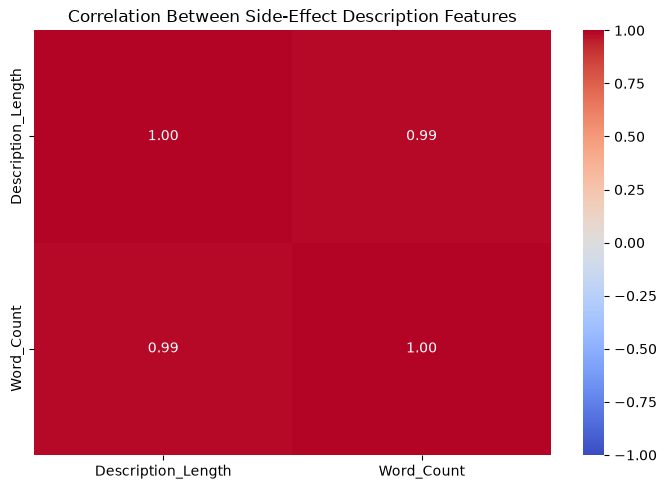

Correlation heatmap generated successfully.


In [16]:
def find_column(keywords):
    for col in df.columns:
        normalized = re.sub(r"[^a-z0-9]", "", str(col).lower())
        if any(word in normalized for word in keywords):
            return col
    return None

side_effect_col = find_column([
    "sideeffects",
    "adversereactions"
])

# 3. Check whether the column exists
if side_effect_col is None:
    print("ERROR: Side-effect column not found.")
    print("Please check the column names printed above.")

else:
    # 4. Create df_analysis
    df_analysis = df.copy()

    # 5. Calculate description features
    descriptions = df_analysis[side_effect_col].fillna("").astype(str)

    df_analysis["Description_Length"] = descriptions.str.len()
    df_analysis["Word_Count"] = descriptions.str.split().str.len()

    # 6. Calculate correlation
    correlation_data = df_analysis[
        ["Description_Length", "Word_Count"]
    ].corr()

    # 7. Plot heatmap
    plt.figure(figsize=(7, 5))

    sns.heatmap(
        correlation_data,
        annot=True,
        cmap="coolwarm",
        fmt=".2f",
        vmin=-1,
        vmax=1
    )

    plt.title("Correlation Between Side-Effect Description Features")
    plt.tight_layout()
    plt.show()

    print("Correlation heatmap generated successfully.")


In [17]:
df.columns = df.columns.str.strip()
df = df.drop_duplicates().copy()

for col in df.select_dtypes(include=["object", "string"]).columns:
    df[col] = df[col].astype("string").str.strip()
    df[col] = df[col].replace("", pd.NA)

print("Data cleaning completed!")
print("Rows after cleaning:", len(df))
display(df.head())

Data cleaning completed!
Rows after cleaning: 11741


,Medicine Name,Composition,Uses,Side_effects,Image URL,Manufacturer,Excellent Review %,Average Review %,Poor Review %
0,Avastin 400mg Injection,Bevacizumab (400mg),Cancer of colon and rectum Non-small cell lung...,Rectal bleeding Taste change Headache Noseblee...,"https://onemg.gumlet.io/l_watermark_346,w_480,...",Roche Products India Pvt Ltd,22,56,22
1,Augmentin 625 Duo Tablet,Amoxycillin (500mg) + Clavulanic Acid (125mg),Treatment of Bacterial infections,Vomiting Nausea Diarrhea Mucocutaneous candidi...,"https://onemg.gumlet.io/l_watermark_346,w_480,...",Glaxo SmithKline Pharmaceuticals Ltd,47,35,18
2,Azithral 500 Tablet,Azithromycin (500mg),Treatment of Bacterial infections,Nausea Abdominal pain Diarrhea,"https://onemg.gumlet.io/l_watermark_346,w_480,...",Alembic Pharmaceuticals Ltd,39,40,21
3,Ascoril LS Syrup,Ambroxol (30mg/5ml) + Levosalbutamol (1mg/5ml)...,Treatment of Cough with mucus,Nausea Vomiting Diarrhea Upset stomach Stomach...,"https://onemg.gumlet.io/l_watermark_346,w_480,...",Glenmark Pharmaceuticals Ltd,24,41,35
4,Aciloc 150 Tablet,Ranitidine (150mg),Treatment of Gastroesophageal reflux disease (...,Headache Diarrhea Gastrointestinal disturbance,"https://onemg.gumlet.io/l_watermark_346,w_480,...",Cadila Pharmaceuticals Ltd,34,37,29


In [18]:
def find_column(keywords):
    for col in df.columns:
        normalized = re.sub(r"[^a-z0-9]", "", col.lower())
        if any(word in normalized for word in keywords):
            return col
    return None

medicine_col = find_column(["medicinename", "drugname", "drug"])
side_effect_col = find_column(["sideeffects", "adversereactions"])
uses_col = find_column(["uses", "indication", "condition"])

print("Medicine column:", medicine_col)
print("Side-effect column:", side_effect_col)
print("Uses column:", uses_col)

if medicine_col is None or side_effect_col is None:
    raise ValueError(
        "Required columns were not detected. Check df.columns.tolist()."
    )

Medicine column: Medicine Name
Side-effect column: Side_effects
Uses column: Uses


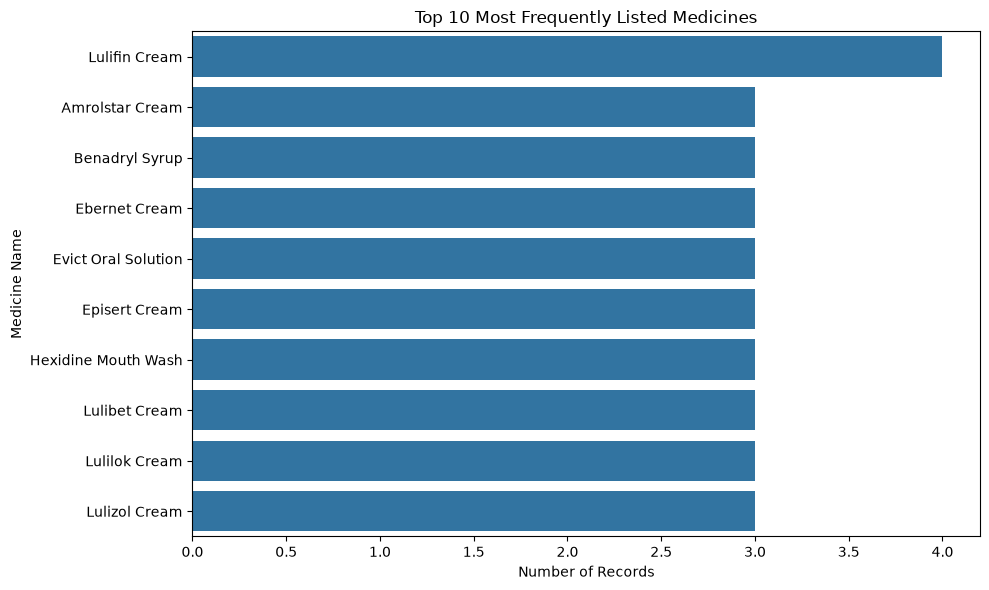

In [19]:
top_medicines = df[medicine_col].dropna().value_counts().head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_medicines.values, y=top_medicines.index)

plt.title("Top 10 Most Frequently Listed Medicines")
plt.xlabel("Number of Records")
plt.ylabel("Medicine Name")
plt.tight_layout()
plt.show()

In [20]:
df_analysis = df.dropna(subset=[side_effect_col]).copy()

df_analysis[side_effect_col] = (
    df_analysis[side_effect_col].astype(str).str.strip()
)

df_analysis = df_analysis[
    df_analysis[side_effect_col].ne("")
].copy()

print("Records available for analysis:", len(df_analysis))
display(df_analysis[[medicine_col, side_effect_col]].head())

Records available for analysis: 11741


,Medicine Name,Side_effects
0,Avastin 400mg Injection,Rectal bleeding Taste change Headache Noseblee...
1,Augmentin 625 Duo Tablet,Vomiting Nausea Diarrhea Mucocutaneous candidi...
2,Azithral 500 Tablet,Nausea Abdominal pain Diarrhea
3,Ascoril LS Syrup,Nausea Vomiting Diarrhea Upset stomach Stomach...
4,Aciloc 150 Tablet,Headache Diarrhea Gastrointestinal disturbance


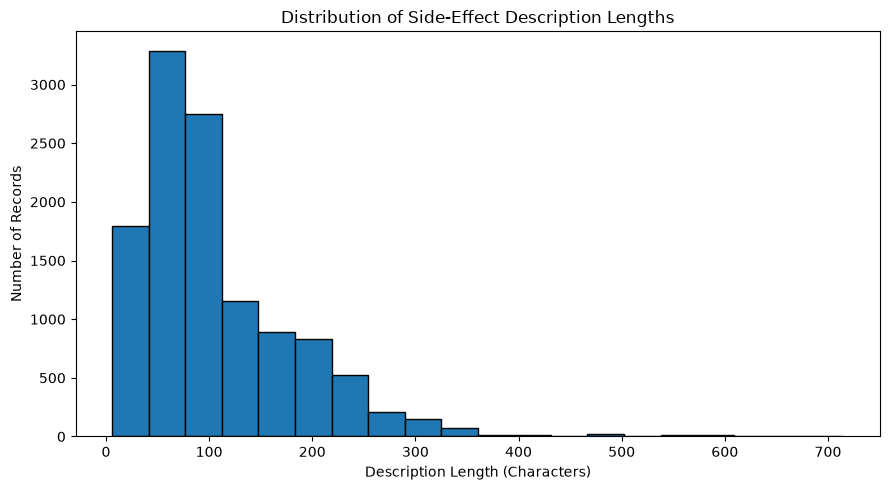

In [21]:
df_analysis["Description_Length"] = (
    df_analysis[side_effect_col].str.len()
)

plt.figure(figsize=(9, 5))
plt.hist(
    df_analysis["Description_Length"],
    bins=20,
    edgecolor="black"
)

plt.title("Distribution of Side-Effect Description Lengths")
plt.xlabel("Description Length (Characters)")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

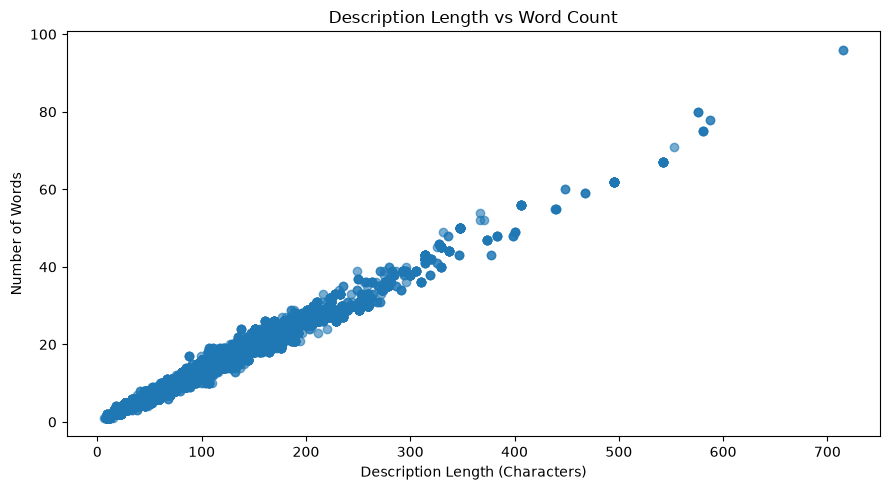

In [22]:
df_analysis["Word_Count"] = (
    df_analysis[side_effect_col].str.split().str.len()
)

plt.figure(figsize=(9, 5))
plt.scatter(
    df_analysis["Description_Length"],
    df_analysis["Word_Count"],
    alpha=0.6
)

plt.title("Description Length vs Word Count")
plt.xlabel("Description Length (Characters)")
plt.ylabel("Number of Words")
plt.tight_layout()
plt.show()

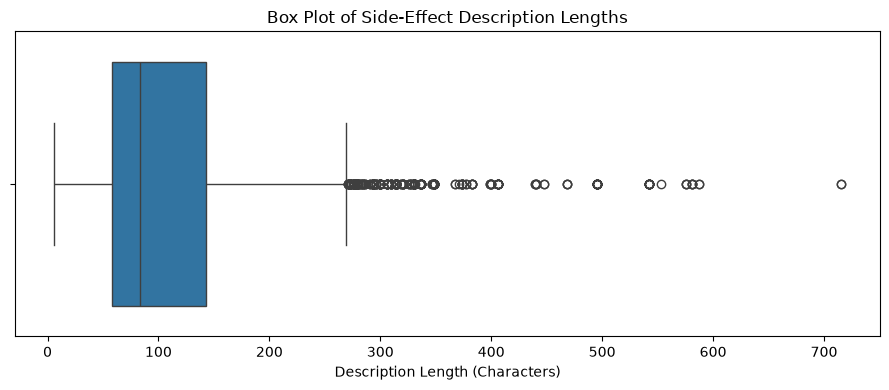

In [23]:
plt.figure(figsize=(9, 4))
sns.boxplot(x=df_analysis["Description_Length"])

plt.title("Box Plot of Side-Effect Description Lengths")
plt.xlabel("Description Length (Characters)")
plt.tight_layout()
plt.show()

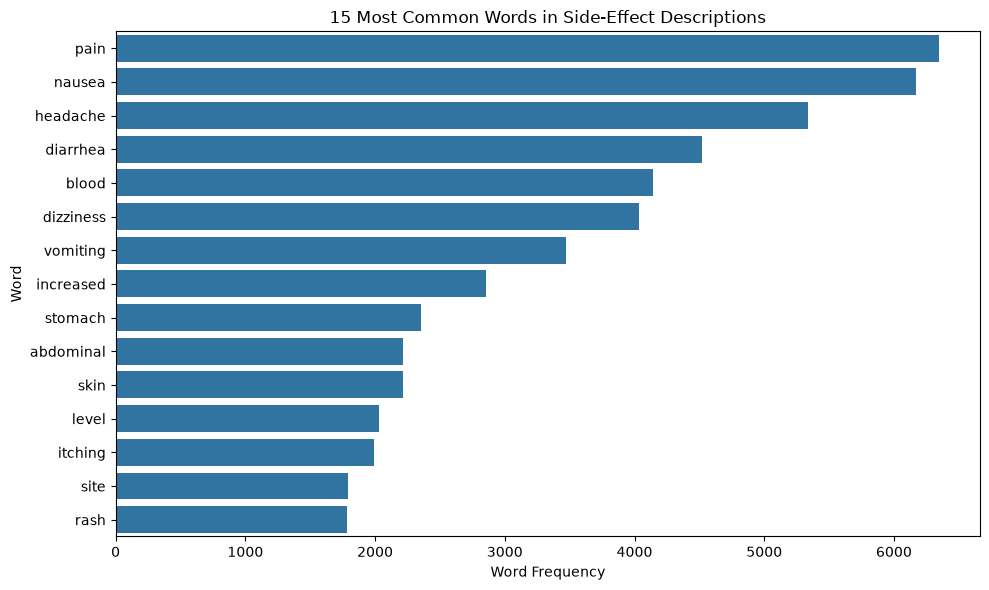

In [24]:
text = " ".join(
    df_analysis[side_effect_col].dropna().str.lower()
)

words = re.findall(r"\b[a-z]{4,}\b", text)

stop_words = {
    "with", "from", "this", "that", "your", "have",
    "been", "more", "less", "very", "when", "after",
    "also", "common", "side", "effects", "effect",
    "medicine", "medicines", "drug"
}

word_counts = Counter(
    word for word in words if word not in stop_words
)

common_words = word_counts.most_common(15)

if common_words:
    word_df = pd.DataFrame(
        common_words,
        columns=["Word", "Frequency"]
    )

    plt.figure(figsize=(10, 6))
    sns.barplot(data=word_df, x="Frequency", y="Word")
    plt.title("15 Most Common Words in Side-Effect Descriptions")
    plt.xlabel("Word Frequency")
    plt.ylabel("Word")
    plt.tight_layout()
    plt.show()
else:
    print("No words available for analysis.")

In [25]:
organ_keywords = {
    "Liver": [
        "liver injury", "hepatotoxicity", "hepatitis",
        "jaundice", "hepatic failure", "liver damage",
        "elevated liver enzymes"
    ],
    "Kidneys": [
        "kidney injury", "renal failure", "renal impairment",
        "nephrotoxicity", "kidney damage", "acute kidney injury"
    ],
    "Heart": [
        "arrhythmia", "cardiac arrest", "heart failure",
        "cardiotoxicity", "myocardial infarction",
        "irregular heartbeat", "palpitations"
    ],
    "Lungs": [
        "lung injury", "pulmonary toxicity", "pneumonitis",
        "respiratory failure", "pulmonary fibrosis",
        "breathing difficulty", "shortness of breath"
    ],
    "Digestive System": [
        "nausea", "vomiting", "diarrhea", "constipation",
        "abdominal pain", "gastritis", "indigestion"
    ]
}

def identify_organs(description):
    description = str(description).lower()
    found = []

    for organ, keywords in organ_keywords.items():
        if any(keyword in description for keyword in keywords):
            found.append(organ)

    return found if found else ["Unclassified"]

df_analysis["Organ_Category"] = (
    df_analysis[side_effect_col].apply(identify_organs)
)

# A description can match more than one organ category.
df_organs = df_analysis.explode("Organ_Category").copy()

print("Organ categorization completed!")
display(
    df_organs[[medicine_col, side_effect_col, "Organ_Category"]].head(10)
)

Organ categorization completed!


,Medicine Name,Side_effects,Organ_Category
0,Avastin 400mg Injection,Rectal bleeding Taste change Headache Noseblee...,Unclassified
1,Augmentin 625 Duo Tablet,Vomiting Nausea Diarrhea Mucocutaneous candidi...,Digestive System
2,Azithral 500 Tablet,Nausea Abdominal pain Diarrhea,Digestive System
3,Ascoril LS Syrup,Nausea Vomiting Diarrhea Upset stomach Stomach...,Heart
3,Ascoril LS Syrup,Nausea Vomiting Diarrhea Upset stomach Stomach...,Digestive System
4,Aciloc 150 Tablet,Headache Diarrhea Gastrointestinal disturbance,Digestive System
5,Allegra 120mg Tablet,Headache Drowsiness Dizziness Nausea,Digestive System
6,Avil 25 Tablet,Sedation,Unclassified
7,Aricep 5 Tablet,Common cold Urinary incontinence Rash Nausea D...,Digestive System
8,Amoxyclav 625 Tablet,Vomiting Nausea Diarrhea Mucocutaneous candidi...,Digestive System


,Organ,Record_Count
0,Digestive System,7885
1,Unclassified,3546
2,Heart,699
3,Liver,75
4,Kidneys,34
5,Lungs,4


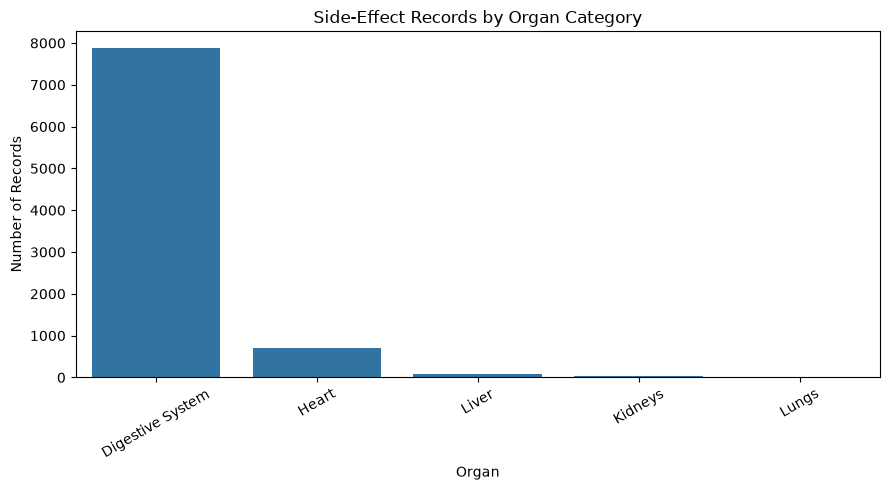

In [26]:
organ_counts = (
    df_organs["Organ_Category"]
    .value_counts()
    .rename_axis("Organ")
    .reset_index(name="Record_Count")
)

display(organ_counts)

plot_data = organ_counts[
    organ_counts["Organ"] != "Unclassified"
]

if not plot_data.empty:
    plt.figure(figsize=(9, 5))
    sns.barplot(data=plot_data, x="Organ", y="Record_Count")

    plt.title("Side-Effect Records by Organ Category")
    plt.xlabel("Organ")
    plt.ylabel("Number of Records")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()
else:
    print("No organ-related keywords matched.")

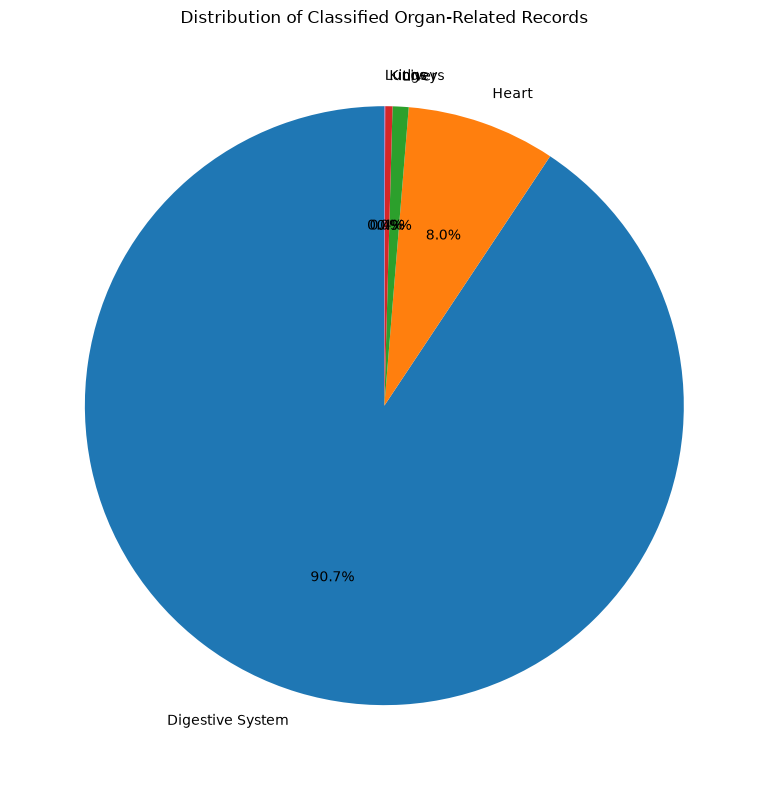

In [27]:
if not plot_data.empty:
    plt.figure(figsize=(8, 8))
    plt.pie(
        plot_data["Record_Count"],
        labels=plot_data["Organ"],
        autopct="%1.1f%%",
        startangle=90
    )

    plt.title("Distribution of Classified Organ-Related Records")
    plt.tight_layout()
    plt.show()

In [28]:
def find_column(keywords):
    for col in df.columns:
        normalized = re.sub(r"[^a-z0-9]", "", str(col).lower())
        if any(word in normalized for word in keywords):
            return col
    return None

medicine_col = find_column(["medicinename", "drugname", "drug"])
side_effect_col = find_column(["sideeffects", "adversereactions"])

print("Medicine column:", medicine_col)
print("Side-effect column:", side_effect_col)

if medicine_col is None or side_effect_col is None:
    print("Please check the column names displayed in Step 1.")
else:
    df_analysis = df.dropna(subset=[side_effect_col]).copy()

    df_analysis[side_effect_col] = (
        df_analysis[side_effect_col].astype(str).str.strip()
    )

    df_analysis = df_analysis[
        df_analysis[side_effect_col].ne("")
    ].copy()

    df_analysis["Description_Length"] = (
        df_analysis[side_effect_col].str.len()
    )

    df_analysis["Word_Count"] = (
        df_analysis[side_effect_col].str.split().str.len()
    )

    print("Analysis DataFrame created:", df_analysis.shape)


Medicine column: Medicine Name
Side-effect column: Side_effects
Analysis DataFrame created: (11741, 11)


In [29]:
classified = df_organs[
    df_organs["Organ_Category"] != "Unclassified"
].copy()

if not classified.empty:
    organ_drug_counts = (
        classified.groupby(["Organ_Category", medicine_col])
        .size()
        .reset_index(name="Record_Count")
    )

    for organ in organ_drug_counts["Organ_Category"].unique():
        subset = (
            organ_drug_counts[
                organ_drug_counts["Organ_Category"] == organ
            ]
            .sort_values("Record_Count", ascending=False)
            .head(10)
        )

        print(f"\nTop listed medicines for {organ}:")
        display(subset)
else:
    print("No classified organ records available.")


Top listed medicines for Digestive System:


,Organ_Category,Medicine Name,Record_Count
1557,Digestive System,Evict Oral Solution,3
3141,Digestive System,Livoluk Oral Solution,3
959,Digestive System,Buscogast 20mg Injection,2
769,Digestive System,Azimax 500 Tablet,2
2871,Digestive System,Lamifin Lotion,2
3847,Digestive System,Mucaine Gel Mint Sugar Free,2
3628,Digestive System,Mibeta SR 40 Tablet,2
2874,Digestive System,Lamitor DT 25 Tablet,2
2498,Digestive System,Involym Capsule,2
2875,Digestive System,Lamitor DT 50 Tablet,2



Top listed medicines for Heart:


,Organ_Category,Medicine Name,Record_Count
7889,Heart,Amrox-LS Syrup,2
8156,Heart,Mibeta SR 40 Tablet,2
8328,Heart,Solvin LS Syrup,2
8345,Heart,Strocit Injection,2
8370,Heart,Telma-AM Tablet,2
8492,Heart,Wikoryl AF Drops,1
7821,Heart,Airtec FB 400 Instacap,1
8508,Heart,Zukamin Cold Suspension,1
7819,Heart,Aginal-AT Tablet,1
7822,Heart,Airtec SF 250 Instacap,1



Top listed medicines for Kidneys:


,Organ_Category,Medicine Name,Record_Count
8509,Kidneys,Genticyn 80mg Injection,1
8510,Kidneys,Grafnos 0.5 Capsule,1
8511,Kidneys,Grafnos 1 Capsule,1
8512,Kidneys,Imunotac 0.5 Capsule,1
8513,Kidneys,Kanamac 1000 Injection,1
8514,Kidneys,Kanamac 500 Injection,1
8515,Kidneys,Kanamac 750 Injection,1
8516,Kidneys,Netromax 300mg Injection,1
8517,Kidneys,Pangraf 0.25 Capsule,1
8518,Kidneys,Pangraf 0.5 Capsule,1



Top listed medicines for Liver:


,Organ_Category,Medicine Name,Record_Count
8543,Liver,Alatro Tablet,1
8544,Liver,Atazor-R 300mg/100mg Tablet,1
8545,Liver,Atchol-ASP Capsule,1
8546,Liver,Atorlip-ASP 10 Capsule,1
8547,Liver,Atorlip-ASP 20 Capsule,1
8548,Liver,Aztor Asp 75 Capsule,1
8549,Liver,Dayo OD 500 Tablet PR,1
8550,Liver,Dayo OD 750 Tablet PR,1
8551,Liver,Depakote 250 Tablet,1
8552,Liver,Depakote XR 250 Tablet,1



Top listed medicines for Lungs:


,Organ_Category,Medicine Name,Record_Count
8618,Lungs,Hydrogem 500mg Capsule,1
8619,Lungs,Leukocel 500mg Capsule,1
8620,Lungs,Myelostat 500mg Capsule,1
8621,Lungs,Riborea Capsule,1


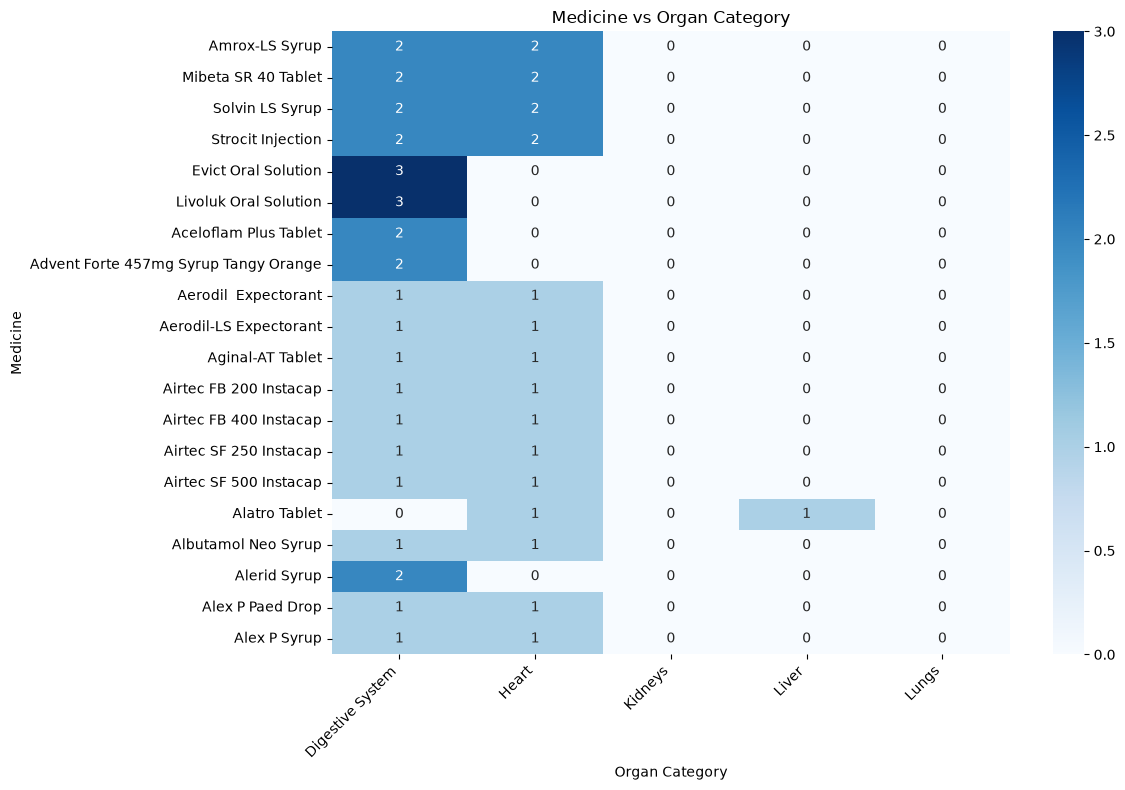

In [30]:
# Remove duplicate index labels
classified = classified.reset_index(drop=True)

# Remove duplicate column names, if any
classified = classified.loc[:, ~classified.columns.duplicated()]

if not classified.empty:
    # Create the medicine vs organ category table
    heatmap_data = pd.crosstab(
        classified[medicine_col].reset_index(drop=True),
        classified["Organ_Category"].reset_index(drop=True)
    )

    # Select the top 20 medicines
    selected = heatmap_data.sum(axis=1).nlargest(20).index
    heatmap_data = heatmap_data.loc[selected]

    # Plot the heatmap
    plt.figure(figsize=(12, 8))

    sns.heatmap(
        heatmap_data,
        annot=True,
        fmt="d",
        cmap="Blues"
    )

    plt.title("Medicine vs Organ Category")
    plt.xlabel("Organ Category")
    plt.ylabel("Medicine")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("No data available for the heatmap.")


In [31]:
# STEP 1: STATISTICAL ANALYSIS

print("STATISTICAL ANALYSIS")
print("=" * 50)

print("\n1. Dataset Overview")
print("Total records:", len(df))
print("Unique medicines:", df[medicine_col].nunique())
print("Missing values:", df.isnull().sum().sum())

print("\n2. Side-Effect Description Statistics")

display(
    df_analysis["Description_Length"].describe().to_frame(
        name="Description Length"
    )
)

display(
    df_analysis["Word_Count"].describe().to_frame(
        name="Word Count"
    )
)

print("\n3. Most Frequently Listed Medicines")

display(
    df_analysis[medicine_col]
    .value_counts()
    .head(15)
    .rename_axis("Medicine")
    .reset_index(name="Record Count")
)

print("\n4. Records by Organ Category")

display(
    df_organs["Organ_Category"]
    .value_counts()
    .rename_axis("Organ")
    .reset_index(name="Record Count")
)

STATISTICAL ANALYSIS

1. Dataset Overview
Total records: 11741
Unique medicines: 11498
Missing values: 0

2. Side-Effect Description Statistics


,Description Length
count,11741.000000
mean,107.442211
std,74.706223
min,6.000000
25%,58.000000
50%,83.000000
75%,143.000000
max,715.000000


,Word Count
count,11741.000000
mean,13.917384
std,9.716132
min,1.000000
25%,8.000000
50%,11.000000
75%,19.000000
max,96.000000



3. Most Frequently Listed Medicines


,Medicine,Record Count
0,Lulifin Cream,4
1,Amrolstar Cream,3
2,Benadryl Syrup,3
3,Ebernet Cream,3
4,Evict Oral Solution,3
5,Episert Cream,3
6,Hexidine Mouth Wash,3
7,Lulibet Cream,3
8,Lulilok Cream,3
9,Lulizol Cream,3



4. Records by Organ Category


,Organ,Record Count
0,Digestive System,7885
1,Unclassified,3546
2,Heart,699
3,Liver,75
4,Kidneys,34
5,Lungs,4


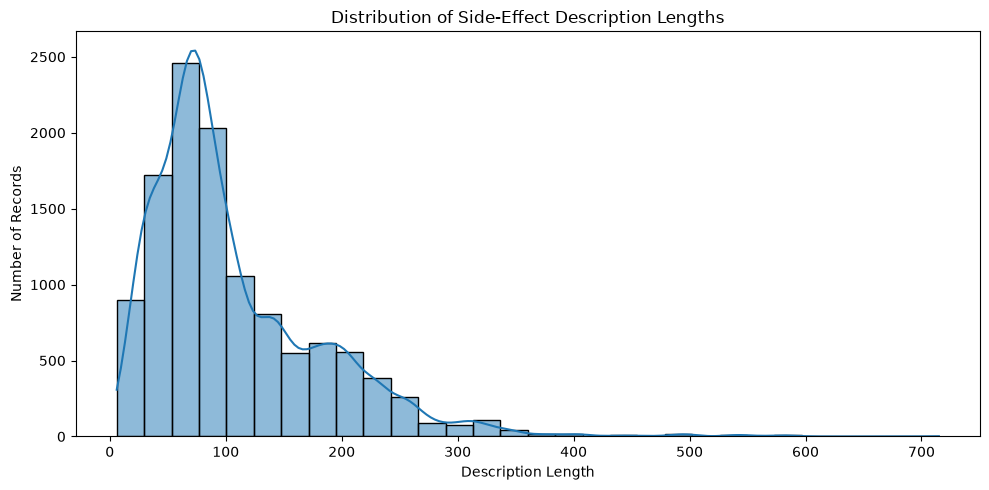

In [32]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_analysis,
    x="Description_Length",
    bins=30,
    kde=True
)

plt.title("Distribution of Side-Effect Description Lengths")
plt.xlabel("Description Length")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

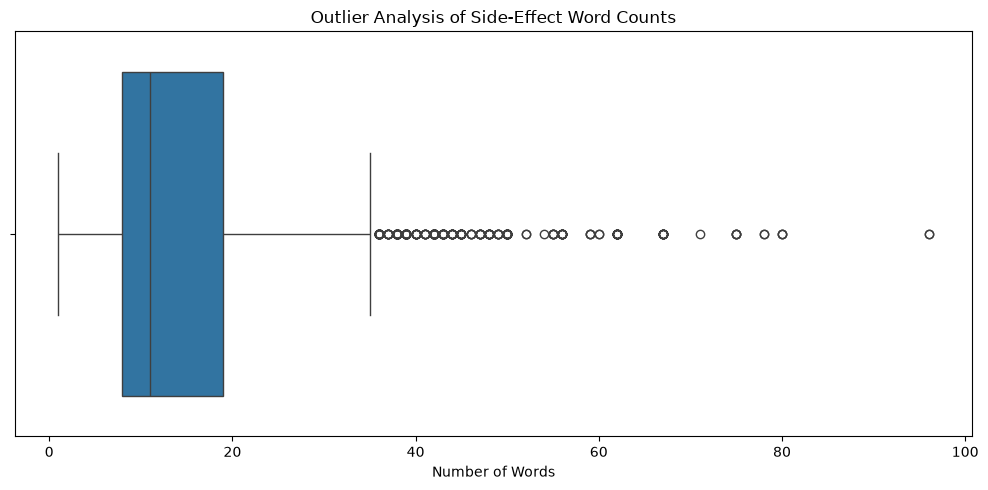

In [33]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df_analysis,
    x="Word_Count"
)

plt.title("Outlier Analysis of Side-Effect Word Counts")
plt.xlabel("Number of Words")
plt.tight_layout()
plt.show()

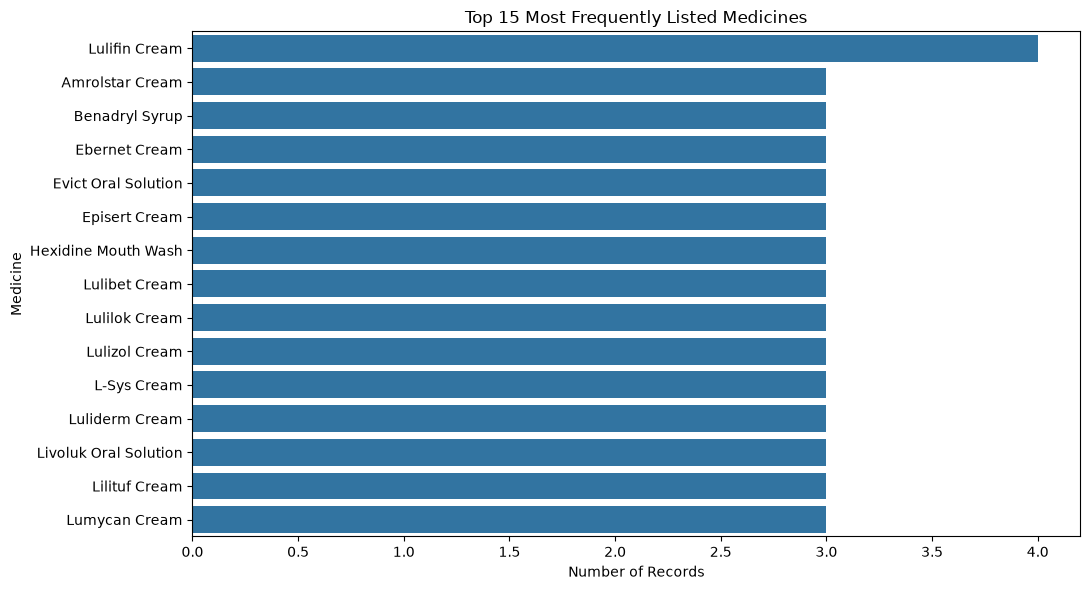

In [34]:
top_15 = (
    df_analysis[medicine_col]
    .value_counts()
    .head(15)
    .reset_index()
)

top_15.columns = ["Medicine", "Record_Count"]

plt.figure(figsize=(11, 6))

sns.barplot(
    data=top_15,
    x="Record_Count",
    y="Medicine"
)

plt.title("Top 15 Most Frequently Listed Medicines")
plt.xlabel("Number of Records")
plt.ylabel("Medicine")
plt.tight_layout()
plt.show()

Medicine-Organ Comparison


Organ_Category,Digestive System,Heart,Kidneys,Liver,Lungs
Medicine,,,,,
A Doxid 100mg Capsule,1,0,0,0,0
AA 5 Tablet,1,0,0,0,0
AB Phylline Capsule,1,0,0,0,0
AB Phylline N Tablet,1,0,0,0,0
AB Phylline SR 200 Tablet,1,0,0,0,0
AB Phylline Syrup,1,0,0,0,0
AB-Flo Capsule,1,0,0,0,0
AB-Flo SR Tablet,1,0,0,0,0
AB-Flo-N Tablet,1,0,0,0,0


,Classified Record Count
Medicine,
Amrox-LS Syrup,4
Mibeta SR 40 Tablet,4
Solvin LS Syrup,4
Strocit Injection,4
Evict Oral Solution,3
Livoluk Oral Solution,3
Ambrodil-LX Drop,2
Ambrodil-LX Syrup,2
Asthakind-DX Syrup Sugar Free,2


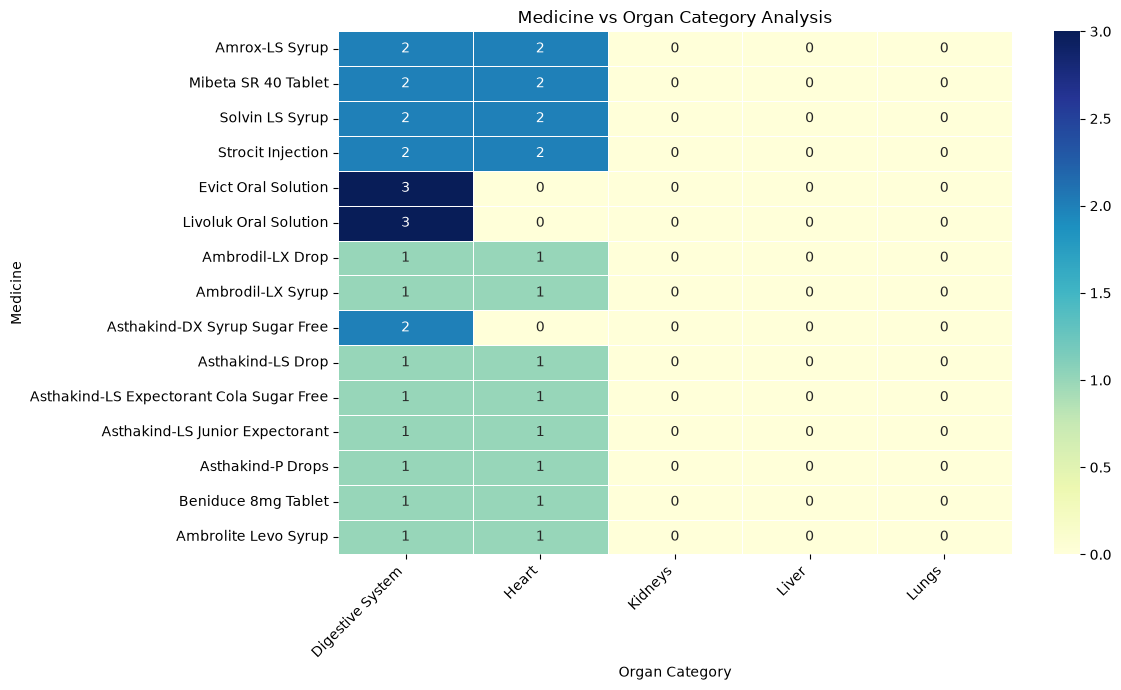

In [35]:
classified = df_organs[
    df_organs["Organ_Category"] != "Unclassified"
].copy()

# Remove duplicate index-label issues
classified = classified.reset_index(drop=True)

# Remove rows with missing medicine or organ category
classified = classified.dropna(
    subset=[medicine_col, "Organ_Category"]
).copy()

# Create Medicine-Organ Comparison Table
medicine_organ_table = pd.crosstab(
    classified[medicine_col].to_numpy(),
    classified["Organ_Category"].to_numpy()
)

# Set meaningful row and column names
medicine_organ_table.index.name = "Medicine"
medicine_organ_table.columns.name = "Organ_Category"

print("Medicine-Organ Comparison")
display(medicine_organ_table.head(20))

# Find medicines with the most classified records
medicine_totals = (
    medicine_organ_table.sum(axis=1)
    .sort_values(ascending=False)
)

display(
    medicine_totals.head(15).to_frame(
        name="Classified Record Count"
    )
)

# Visualize the top 15 medicines
top_medicine_names = medicine_totals.head(15).index

top_medicine_organ = medicine_organ_table.loc[
    top_medicine_names
]

plt.figure(figsize=(12, 7))

sns.heatmap(
    top_medicine_organ,
    annot=True,
    fmt="d",
    cmap="YlGnBu",
    linewidths=0.5
)

plt.title("Medicine vs Organ Category Analysis")
plt.xlabel("Organ Category")
plt.ylabel("Medicine")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


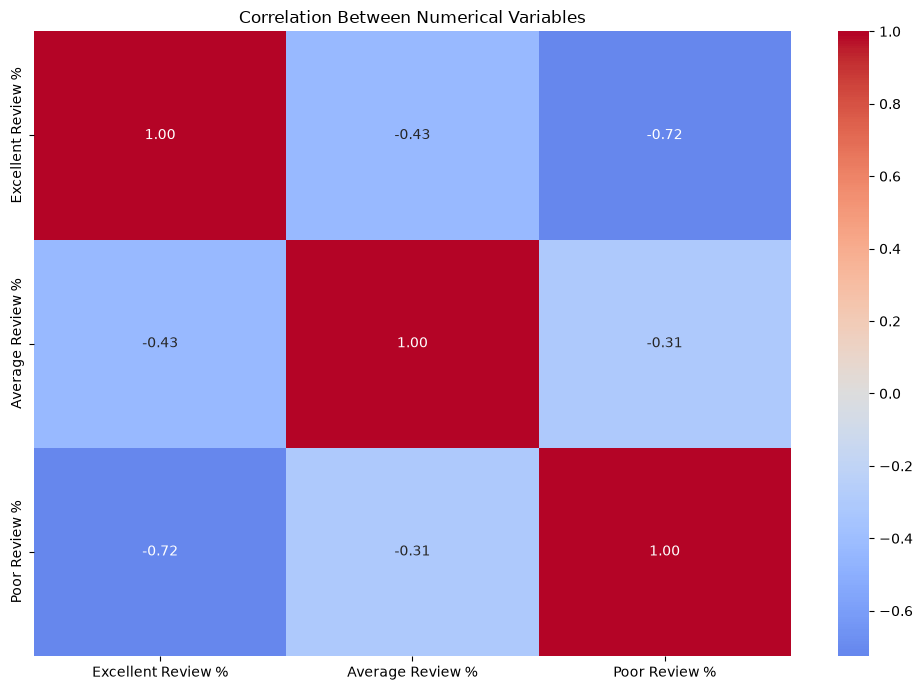

,Excellent Review %,Average Review %,Poor Review %
Excellent Review %,1.000000,-0.428875,-0.724835
Average Review %,-0.428875,1.000000,-0.311483
Poor Review %,-0.724835,-0.311483,1.000000


In [36]:
# STEP 4: NUMERICAL CORRELATION ANALYSIS

numeric_df = df.select_dtypes(include=np.number)

if numeric_df.shape[1] >= 2:

    correlation_matrix = numeric_df.corr()

    plt.figure(figsize=(10, 7))

    sns.heatmap(
        correlation_matrix,
        annot=True,
        cmap="coolwarm",
        fmt=".2f",
        center=0
    )

    plt.title("Correlation Between Numerical Variables")
    plt.tight_layout()
    plt.show()

    display(correlation_matrix)

else:
    print("Insufficient numerical columns for correlation analysis.")
    print("Available numerical columns:", numeric_df.columns.tolist())

Clustering completed!


Organ_Category,Digestive System,Heart,Kidneys,Liver,Lungs,Cluster
Medicine Name,,,,,,
Zyrova 5 Tablet,1,0,0,0,0,0
AA 5 Tablet,1,0,0,0,0,0
AB Phylline Capsule,1,0,0,0,0,0
AB Phylline N Tablet,1,0,0,0,0,0
AB Phylline SR 200 Tablet,1,0,0,0,0,0
AB Phylline Syrup,1,0,0,0,0,0
AB-Flo Capsule,1,0,0,0,0,0
AB-Flo SR Tablet,1,0,0,0,0,0
AB-Flo-N Tablet,1,0,0,0,0,0


Silhouette Score: 0.909


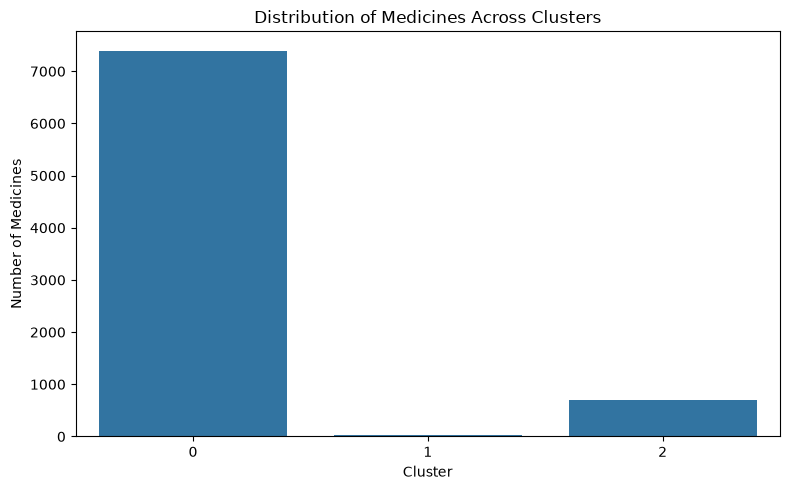

In [37]:
# STEP 5: K-MEANS CLUSTERING

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

# Create medicine-organ profile
cluster_data = pd.crosstab(
    classified[medicine_col],
    classified["Organ_Category"]
)

# Remove medicines with no classified records
cluster_data = cluster_data.loc[
    cluster_data.sum(axis=1) > 0
]

if len(cluster_data) >= 3 and cluster_data.shape[1] >= 2:

    # Scale features
    scaler = StandardScaler()

    scaled_data = scaler.fit_transform(cluster_data)

    # Choose 3 clusters, or fewer if the dataset is small
    n_clusters = min(3, len(cluster_data) - 1)

    kmeans = KMeans(
        n_clusters=n_clusters,
        random_state=42,
        n_init=10
    )

    cluster_labels = kmeans.fit_predict(scaled_data)

    cluster_results = cluster_data.copy()
    cluster_results["Cluster"] = cluster_labels

    print("Clustering completed!")

    display(
        cluster_results.sort_values("Cluster").head(30)
    )

    # Evaluate clustering
    if len(set(cluster_labels)) > 1:
        score = silhouette_score(
            scaled_data,
            cluster_labels
        )

        print("Silhouette Score:", round(score, 3))

    # Plot cluster distribution
    plt.figure(figsize=(8, 5))

    sns.countplot(
        x=cluster_labels
    )

    plt.title("Distribution of Medicines Across Clusters")
    plt.xlabel("Cluster")
    plt.ylabel("Number of Medicines")
    plt.tight_layout()
    plt.show()

else:
    print(
        "Not enough medicines or organ categories "
        "for meaningful clustering."
    )

,Number of Clusters,Silhouette Score
0,2,0.906392
1,3,0.909027
2,4,0.937322
3,5,0.942661
4,6,0.979845
5,7,0.996105
6,8,0.997951


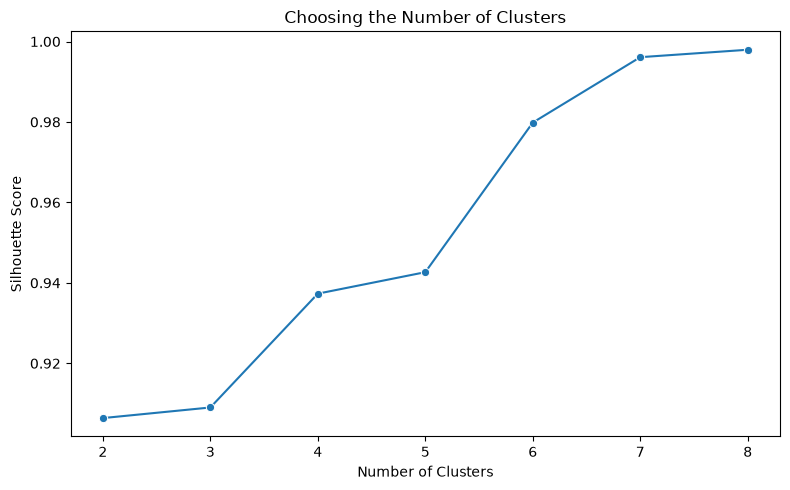

Best candidate based on silhouette score: 8


In [38]:
# STEP 6: CLUSTER EVALUATION

if len(cluster_data) >= 4 and cluster_data.shape[1] >= 2:

    scores = []

    max_k = min(8, len(cluster_data) - 1)

    for k in range(2, max_k + 1):

        model = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=10
        )

        labels = model.fit_predict(scaled_data)

        if len(set(labels)) > 1:
            score = silhouette_score(
                scaled_data,
                labels
            )

            scores.append((k, score))

    if scores:

        score_df = pd.DataFrame(
            scores,
            columns=["Number of Clusters", "Silhouette Score"]
        )

        display(score_df)

        plt.figure(figsize=(8, 5))

        sns.lineplot(
            data=score_df,
            x="Number of Clusters",
            y="Silhouette Score",
            marker="o"
        )

        plt.title("Choosing the Number of Clusters")
        plt.tight_layout()
        plt.show()

        best_k = score_df.loc[
            score_df["Silhouette Score"].idxmax(),
            "Number of Clusters"
        ]

        print("Best candidate based on silhouette score:", int(best_k))

    else:
        print("Could not calculate valid silhouette scores.")

else:
    print("Insufficient data to compare cluster counts.")

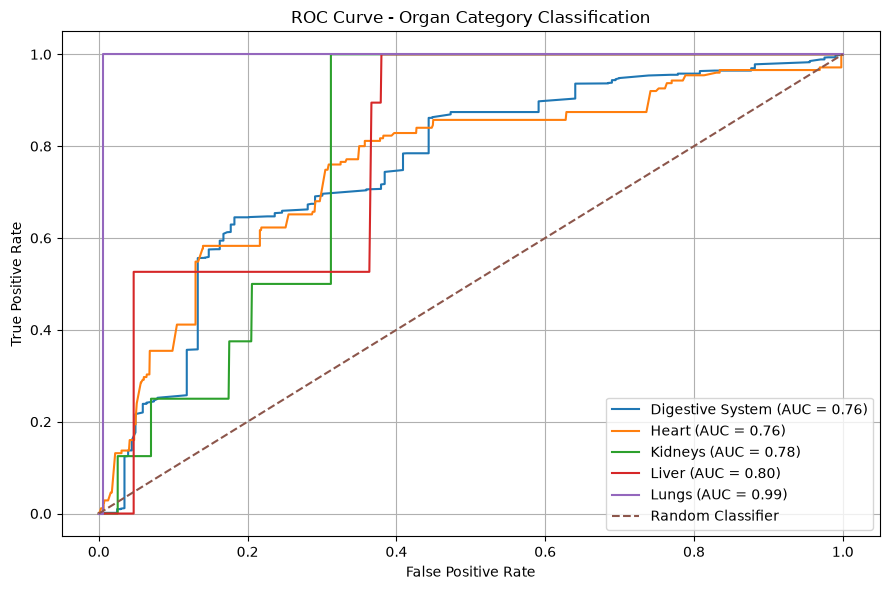

In [39]:
roc_df = df_organs.copy()

# Reset index to prevent duplicate-index alignment errors
roc_df = roc_df.reset_index(drop=True)

# Extract organ label if stored as a single-item list
roc_df["Organ_Category"] = roc_df["Organ_Category"].apply(
    lambda x: x[0] if isinstance(x, list) and len(x) == 1
    else x if isinstance(x, str)
    else np.nan
)

# Remove missing and unclassified records
roc_df = roc_df.dropna(
    subset=["Organ_Category"]
).copy()

roc_df = roc_df[
    roc_df["Organ_Category"] != "Unclassified"
].copy()

# Create description features if missing
if "Description_Length" not in roc_df.columns:
    roc_df["Description_Length"] = (
        roc_df[side_effect_col].fillna("").astype(str).str.len()
    )

if "Word_Count" not in roc_df.columns:
    roc_df["Word_Count"] = (
        roc_df[side_effect_col].fillna("").astype(str).str.split().str.len()
    )

# Select features and remove invalid values
roc_df["Description_Length"] = pd.to_numeric(
    roc_df["Description_Length"], errors="coerce"
)
roc_df["Word_Count"] = pd.to_numeric(
    roc_df["Word_Count"], errors="coerce"
)

roc_df = roc_df.replace([np.inf, -np.inf], np.nan)
roc_df = roc_df.dropna(
    subset=["Description_Length", "Word_Count", "Organ_Category"]
).copy()

# Encode organ categories
encoder = LabelEncoder()
y = encoder.fit_transform(roc_df["Organ_Category"])

X = roc_df[["Description_Length", "Word_Count"]]

# Check whether ROC analysis is possible
if len(np.unique(y)) >= 2:

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.25,
        random_state=42,
        stratify=y
    )

    # Train classification model
    model = make_pipeline(
        StandardScaler(),
        OneVsRestClassifier(
            LogisticRegression(max_iter=1000)
        )
    )

    model.fit(X_train, y_train)

    # Predict probabilities
    y_prob = model.predict_proba(X_test)

    # Convert labels to one-vs-rest format
    classes = model.named_steps[
        "onevsrestclassifier"
    ].classes_

    y_test_binary = label_binarize(
        y_test, classes=classes
    )

    # Plot ROC curves
    plt.figure(figsize=(9, 6))

    for i, category in enumerate(classes):
        if len(np.unique(y_test_binary[:, i])) < 2:
            continue

        fpr, tpr, thresholds = roc_curve(
            y_test_binary[:, i],
            y_prob[:, i]
        )

        roc_auc = auc(fpr, tpr)

        plt.plot(
            fpr,
            tpr,
            label=f"{encoder.classes_[category]} (AUC = {roc_auc:.2f})"
        )

    plt.plot(
        [0, 1], [0, 1],
        linestyle="--",
        label="Random Classifier"
    )

    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curve - Organ Category Classification")
    plt.legend(loc="lower right")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

else:
    print("ROC curve requires at least two organ categories.")


In [41]:
print("Total cleaned records:", len(df))
print("Records with side-effect descriptions:", len(df_analysis))
print("Distinct medicines:", df_analysis[medicine_col].nunique())
print("Organ categories:", len(plot_data))

print("\nOrgan-wise record counts:")
display(organ_counts)

print("\nProject analysis completed!")

Total cleaned records: 11741
Records with side-effect descriptions: 11741
Distinct medicines: 11498
Organ categories: 5

Organ-wise record counts:


,Organ,Record_Count
0,Digestive System,7885
1,Unclassified,3546
2,Heart,699
3,Liver,75
4,Kidneys,34
5,Lungs,4



Project analysis completed!
